In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fft, fftfreq
import scipy.stats
import plotly.graph_objects as go
from scipy.io import savemat

import json
import glob
import os
import sys
import re
from tqdm import tqdm

from EggFileReaderHamm import EggFileReader

In [2]:
import numpy as np
import plotly.graph_objects as go
import os, re

def createPSD(filepath, slices, window, fs=403e6):
    file = EggFileReader(filepath)
    _, data_freq = file.quick_load_fft_stream_hamm(dft_window=window) 

    data = data_freq[0][0][:slices, :]  

    nBins = data.shape[1] // 2
    psd = np.abs(data[:, :nBins])**2
    psd = psd.T

    freqs = np.fft.rfftfreq(window, 1/fs)[:nBins]
    times = np.arange(slices) * (window / fs)

    filename = os.path.basename(filepath)
    match = re.search(r'Angle([-\d.]+)', filename)
    pitch_angle = float(match.group(1)) if match else None

    return psd, freqs, times, pitch_angle



def plotSpectrogramNew(
    psd, freqs, times, pitchAngle,
    highlights=None,
    threshold_dB=None,
    threshold_rel_dB=None,  
    log_color=True,
    col='Viridis',
    debug_threshold=True
):
    """
    Plot spectrogram with optional highlights.

    threshold_dB: absolute threshold in dB (if log_color=True) or linear (if log_color=False)
    threshold_rel_dB: relative threshold from max (only meaningful when log_color=True)
    """

    # Convert PSD to dB (or keep linear)
    if log_color:
        psd_to_plot = 10 * np.log10(psd + 1e-12)
        zlabel = "Power (dB)"
    else:
        psd_to_plot = psd
        zlabel = "Power"

    # Heatmap
    fig = go.Figure(data=go.Heatmap(
        z=psd_to_plot,
        x=times * 1e6,
        y=freqs / 1e6,
        colorscale=col,
        colorbar=dict(title=zlabel),
        zmin=np.nanmin(psd_to_plot),
        zmax=np.nanmax(psd_to_plot),
    ))

    # Decide highlights
    highlight_points = []

    # If user passed explicit highlight list, use it
    if highlights is not None:
        highlight_points = highlights

    # Otherwise compute from thresholding
    else:
        thr = None
        if threshold_rel_dB is not None:
            if not log_color:
                raise ValueError("threshold_rel_dB requires log_color=True (dB scale).")
            thr = np.nanmax(psd_to_plot) - float(threshold_rel_dB)
        elif threshold_dB is not None:
            thr = float(threshold_dB)

        if thr is not None:
            mask = np.isfinite(psd_to_plot) & (psd_to_plot >= thr)
            idxs = np.where(mask)

            if debug_threshold:
                vmin = np.nanmin(psd_to_plot)
                vmax = np.nanmax(psd_to_plot)
                npts = idxs[0].size
                print(f"[threshold debug] zmin={vmin:.2f}, zmax={vmax:.2f}, thr={thr:.2f}, n_highlight={npts}")

            highlight_points = [(times[j], freqs[i], psd_to_plot[i, j]) for i, j in zip(idxs[0], idxs[1])]

    #Plot highlights
    if len(highlight_points) > 0:
        ht, hf, _ = zip(*highlight_points)
        fig.add_trace(go.Scatter(
            x=np.array(ht) * 1e6,
            y=np.array(hf) / 1e6,
            mode='markers',
            marker=dict(color='red', size=6, symbol='x'),
            name='Highlighted'
        ))

    fig.update_layout(
        width=900,
        height=700,
        title={'text': f"Spectrogram (Angle {pitchAngle})", 'x': 0.5, 'xanchor': 'center'},
        xaxis_title="Time (µs)",
        yaxis_title="Frequency (MHz)"
    )

    fig.show()


In [3]:
filepath_prefix = '/gpfs/gibbs/pi/heeger/spreadsheetData/SpreadsheetRow51_UNetScattering_CCA/Trap_CCA_long_trap_44_UNetScattering_0/results/'
#filepath = filepath_prefix + '1261225988165-375/locust_mc_Seed600_Angle90.0000000_Pos0.0040000_Energy18505.000000.egg'
#filepath = filepath_prefix + '1201225989298-810/locust_mc_Seed600_Angle88.7000000_Pos0.0030000_Energy18570.000000.egg'
# filepath = filepath_prefix + '1191225859438-054/locust_mc_Seed600_Angle88.4500000_Pos0.0040000_Energy18540.000000.egg'
# filepath = filepath_prefix + '1211225014786-642/locust_mc_Seed600_Angle89.0000000_Pos0.0050000_Energy18585.000000.egg'
# filepath = filepath_prefix + '1191225838630-993/locust_mc_Seed600_Angle88.5500000_Pos0.0040000_Energy18505.000000.egg'
filepath = filepath_prefix + '1181225825176-462/locust_mc_Seed600_Angle88.0000000_Pos0.0040000_Energy18510.000000.egg'
slices = 600
window = 4096
psdArray, freq, times, pitch_angle = createPSD(filepath, slices, window)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/gpfs/gibbs/pi/heeger/spreadsheetData/SpreadsheetRow51_UNetScattering_CCA/Trap_CCA_long_trap_44_UNetScattering_0/results/1181225825176-462/locust_mc_Seed600_Angle88.0000000_Pos0.0040000_Energy18510.000000.egg', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

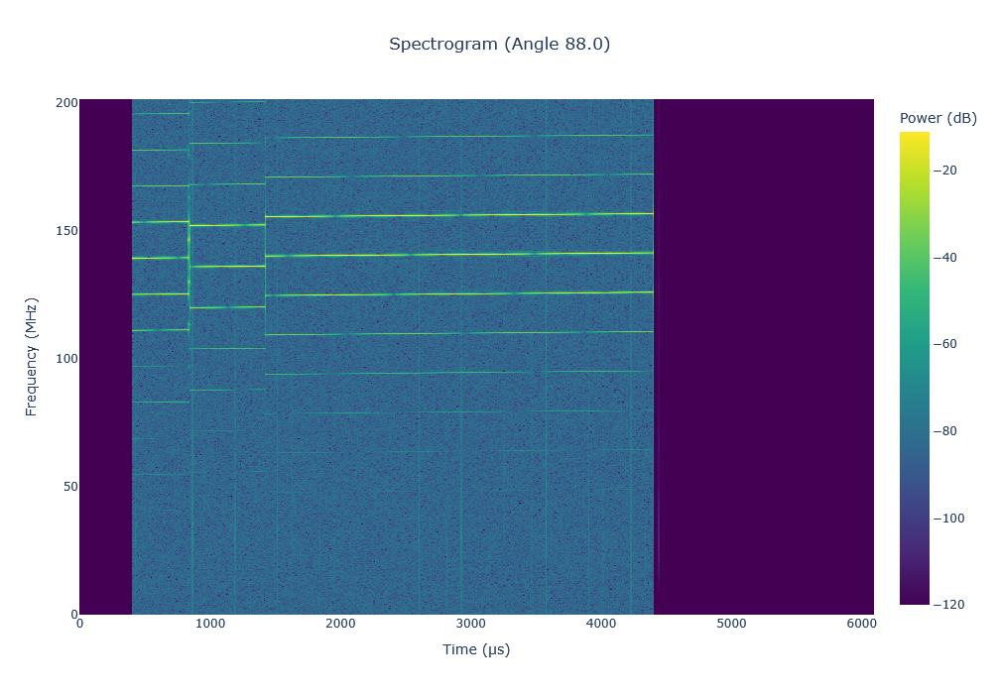

In [10]:
plotSpectrogramNew(
    psdArray, freq, times, pitch_angle,
    highlights=None,
    threshold_dB=None,
    threshold_rel_dB=None,  
    log_color=True,
    col='Viridis',
    debug_threshold=True
)